# Sistemas de recuperación de información, RAG y LangChain
## Sesión 1 — De los vectores a un mini sistema de *retrieval*

Este notebook acompaña la primera sesión y también está pensado para poder estudiarse de forma autónoma.

**Objetivos.** Al terminar deberías poder:

1. formular un problema básico de recuperación de información;
2. interpretar y manipular vectores con Python estándar;
3. calcular magnitudes, distancias y similitudes;
4. explicar por qué la métrica, la escala y la normalización cambian los resultados;
5. construir un sistema mínimo de *scoring*, *ranking* y *top-k*.


## 1. El problema de recuperación de información

Un sistema de recuperación de información recibe una **consulta** (*query*) y busca en una **colección** los elementos más relevantes. No se limita a decidir si un documento coincide o no: normalmente asigna una puntuación y devuelve un orden.

$$\text{consulta} \longrightarrow \text{scoring de candidatos} \longrightarrow \text{ranking} \longrightarrow \text{top-k}$$

Ejemplos: un buscador web, la búsqueda de productos, la recomendación de contenidos o la selección de fragmentos que un sistema RAG entregará a un modelo generativo.

Primero veremos una búsqueda literal muy sencilla. Es útil como punto de partida, pero no entiende significado, sinónimos ni contexto.


In [23]:
documentos = [
    "Introducción a los sistemas de recuperación de información",
    "Representaciones vectoriales de texto",
    "Generación aumentada mediante recuperación o RAG",
    "Fundamentos de bases de datos relacionales",
]

consulta = "recuperación"

coincidencias = [
    documento
    for documento in documentos
    if consulta.lower() in documento.lower()
]

print(f"Consulta: {consulta!r}")
print("Resultados literales:")
for documento in coincidencias:
    print("-", documento)


Consulta: 'recuperación'
Resultados literales:
- Introducción a los sistemas de recuperación de información
- Generación aumentada mediante recuperación o RAG


La pregunta que guiará la sesión es: **¿cómo convertimos una consulta y una colección en objetos matemáticos comparables?** Una respuesta central consiste en representarlos mediante vectores dentro de un espacio común.


## 2. Vectores y espacios vectoriales

Un vector es una secuencia ordenada de números. En Python puro podemos representarlo con una lista o una tupla:

$$\mathbf{x} = (x_1, x_2, \ldots, x_n)$$

Cada posición describe una propiedad o **componente**. Un espacio vectorial establece el número de componentes y permite realizar operaciones coherentes entre vectores del mismo espacio.

Aquí usaremos una representación didáctica con tres componentes:

1. frecuencia de la palabra “recuperación”;
2. frecuencia de “vector”;
3. frecuencia de “base de datos”.

El significado no está en el número aislado, sino en la correspondencia estable entre **posición** y **característica**.


In [24]:
caracteristicas = ("recuperación", "vector", "base de datos")

documento_a = [3, 1, 0]
documento_b = [0, 1, 4]

for nombre, vector in (("A", documento_a), ("B", documento_b)):
    print(f"Documento {nombre}: {vector}")
    for caracteristica, valor in zip(caracteristicas, vector):
        print(f"  {caracteristica:15s} -> {valor}")


Documento A: [3, 1, 0]
  recuperación    -> 3
  vector          -> 1
  base de datos   -> 0
Documento B: [0, 1, 4]
  recuperación    -> 0
  vector          -> 1
  base de datos   -> 4


### Componentes y dimensionalidad

La **dimensionalidad** es el número de componentes del vector. Dos vectores solo pueden compararse componente a componente si pertenecen al mismo espacio y comparten la misma interpretación.

- $(2, 5)$ vive en 2 dimensiones.
- $(2, 5, 1)$ vive en 3 dimensiones.
- Tener la misma longitud no basta: $(edad, altura)$ y $(precio, stock)$ no comparten significado.


In [25]:
def misma_dimension(a, b):
    """Indica si dos vectores tienen el mismo número de componentes."""
    return len(a) == len(b)


def comprobar_mismo_espacio(a, b):
    """Detiene el cálculo con un mensaje claro si las dimensiones no coinciden."""
    if not misma_dimension(a, b):
        raise ValueError(
            f"Dimensiones incompatibles: {len(a)} frente a {len(b)}"
        )


print("Dimensión de documento_a:", len(documento_a))
print("¿A y B tienen la misma dimensión?", misma_dimension(documento_a, documento_b))
print("¿[1, 2] y [1, 2, 3]?", misma_dimension([1, 2], [1, 2, 3]))


Dimensión de documento_a: 3
¿A y B tienen la misma dimensión? True
¿[1, 2] y [1, 2, 3]? False


### Interpretación geométrica

Un vector también puede interpretarse como un punto o como un desplazamiento desde el origen.

- En 1D: una posición sobre una recta.
- En 2D: un punto $(x, y)$ en un plano.
- En 3D: un punto $(x, y, z)$ en el espacio.
- En más dimensiones: la intuición geométrica sigue siendo válida aunque no podamos dibujarlo directamente.

Para $(3, 2)$, avanzamos 3 unidades en el eje horizontal y 2 en el vertical. 


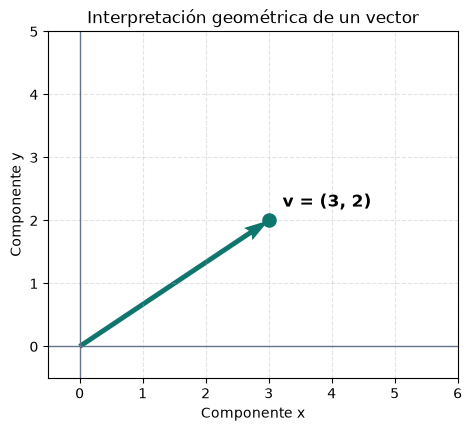

In [27]:
import matplotlib.pyplot as plt


def dibujar_vector_2d(vector, limites=(6, 5)):
    """Representa un vector 2D como una flecha que parte del origen."""
    x, y = vector
    ancho, alto = limites

    fig, ax = plt.subplots(figsize=(7, 4.5))
    ax.axhline(0, color="#64748b", linewidth=1)
    ax.axvline(0, color="#64748b", linewidth=1)
    ax.grid(True, linestyle="--", alpha=0.35)

    ax.quiver(
        0, 0, x, y,
        angles="xy", scale_units="xy", scale=1,
        color="#0f766e", width=0.012,
    )
    ax.scatter(x, y, s=90, color="#0f766e", zorder=3)
    ax.annotate(
        f"v = ({x}, {y})",
        (x, y), xytext=(10, 10), textcoords="offset points",
        fontsize=12, weight="bold",
    )

    ax.set_xlim(-0.5, ancho)
    ax.set_ylim(-0.5, alto)
    ax.set_aspect("equal")
    ax.set_xlabel("Componente x")
    ax.set_ylabel("Componente y")
    ax.set_title("Interpretación geométrica de un vector")
    plt.show()


vector_2d = (3, 2)  # ✏️ Prueba, por ejemplo, (5, 4)
dibujar_vector_2d(vector_2d)

## 3. Operaciones básicas con vectores

Las operaciones se aplican **componente a componente**:

$$\mathbf{a}+\mathbf{b}=(a_1+b_1,\ldots,a_n+b_n)$$

$$\mathbf{a}-\mathbf{b}=(a_1-b_1,\ldots,a_n-b_n)$$

Multiplicar por un escalar cambia la longitud y, si el escalar es negativo, también invierte la dirección:

$$c\mathbf{a}=(ca_1,\ldots,ca_n)$$


In [5]:
def sumar(a, b):
    comprobar_mismo_espacio(a, b)
    return [x + y for x, y in zip(a, b)]


def restar(a, b):
    comprobar_mismo_espacio(a, b)
    return [x - y for x, y in zip(a, b)]


def escalar(c, vector):
    return [c * x for x in vector]


a = [2, 1]
b = [1, 3]

print("a + b =", sumar(a, b))
print("a - b =", restar(a, b))
print("2a    =", escalar(2, a))
print("-a    =", escalar(-1, a))


a + b = [3, 4]
a - b = [1, -2]
2a    = [4, 2]
-a    = [-2, -1]


### Microejercicio 1 — Predice antes de ejecutar

Sean $u=[1,-2,3]$ y $v=[4,0,-1]$:

1. ¿Cuánto vale $u+v$?
2. ¿Cuánto vale $u-v$?
3. ¿Cuánto vale $3u$?

La celda comprueba automáticamente las respuestas. Puedes cambiar `respuesta_...` para experimentar.


In [6]:
u = [1, -2, 3]
v = [4, 0, -1]

respuesta_suma = [5, -2, 2]
respuesta_resta = [-3, -2, 4]
respuesta_escalar = [3, -6, 9]

assert respuesta_suma == sumar(u, v), "Revisa la suma componente a componente"
assert respuesta_resta == restar(u, v), "Revisa el orden: estamos calculando u - v"
assert respuesta_escalar == escalar(3, u), "Multiplica cada componente por 3"

print("✓ Las tres respuestas son correctas")


✓ Las tres respuestas son correctas


## 4. Magnitud y normalización

La **magnitud** o norma euclídea mide la longitud de un vector:

$$\|\mathbf{x}\|_2=\sqrt{x_1^2+x_2^2+\cdots+x_n^2}$$

Normalizar consiste en dividir cada componente por la magnitud para obtener un vector de longitud 1:

$$\hat{\mathbf{x}}=\frac{\mathbf{x}}{\|\mathbf{x}\|_2}$$

La normalización conserva la dirección, pero elimina el tamaño. El vector cero es un caso especial: no tiene dirección y no puede dividirse por una magnitud igual a cero.


In [7]:
from math import sqrt


def magnitud(vector):
    return sqrt(sum(x ** 2 for x in vector))


def normalizar(vector):
    longitud = magnitud(vector)
    if longitud == 0:
        raise ValueError("El vector cero no se puede normalizar")
    return [x / longitud for x in vector]


vector = [3, 4]
vector_normalizado = normalizar(vector)

print("Vector original:", vector)
print("Magnitud:", magnitud(vector))
print("Vector normalizado:", vector_normalizado)
print("Magnitud tras normalizar:", magnitud(vector_normalizado))


Vector original: [3, 4]
Magnitud: 5.0
Vector normalizado: [0.6, 0.8]
Magnitud tras normalizar: 1.0


In [8]:
# Pequeñas comprobaciones numéricas: con decimales es preferible usar tolerancia.
def casi_igual(a, b, tolerancia=1e-9):
    return abs(a - b) < tolerancia


assert casi_igual(magnitud([3, 4]), 5.0)
assert casi_igual(magnitud(normalizar([3, 4])), 1.0)
print("✓ La normalización produce longitud 1")


✓ La normalización produce longitud 1


## 5. Distancias entre vectores

Una distancia expresa cuán separados están dos puntos. Menor distancia significa mayor cercanía, pero **la noción de cercanía depende de la métrica**.

### Distancia euclídea ($L_2$)

La distancia “en línea recta”:

$$d_2(\mathbf{a},\mathbf{b})=\sqrt{\sum_i |a_i-b_i|^2}$$

### Distancia Manhattan ($L_1$)

Suma de los desplazamientos por cada eje:

$$d_1(\mathbf{a},\mathbf{b})=\sum_i |a_i-b_i|$$

### Distancia de Minkowski ($L_p$)

Generaliza las anteriores:

$$d_p(\mathbf{a},\mathbf{b})=\left(\sum_i |a_i-b_i|^p\right)^{1/p},\quad p\geq1$$

- $p=1$: Manhattan.
- $p=2$: euclídea.

### Distancia de Chebyshev ($L_\infty$)

Solo importa la mayor diferencia en una componente:

$$d_\infty(\mathbf{a},\mathbf{b})=\max_i |a_i-b_i|$$


In [9]:
def distancia_minkowski(a, b, p=2):
    comprobar_mismo_espacio(a, b)
    if p < 1:
        raise ValueError("Para ser una distancia, p debe ser mayor o igual que 1")
    return sum(abs(x - y) ** p for x, y in zip(a, b)) ** (1 / p)


def distancia_euclidea(a, b):
    return distancia_minkowski(a, b, p=2)


def distancia_manhattan(a, b):
    return distancia_minkowski(a, b, p=1)


def distancia_chebyshev(a, b):
    comprobar_mismo_espacio(a, b)
    if not a:
        raise ValueError("La distancia necesita vectores no vacíos")
    return max(abs(x - y) for x, y in zip(a, b))


a = [1, 2]
b = [4, 6]

print("Euclídea: ", distancia_euclidea(a, b))
print("Manhattan: ", distancia_manhattan(a, b))
print("Minkowski p=3:", distancia_minkowski(a, b, p=3))
print("Chebyshev:", distancia_chebyshev(a, b))


Euclídea:  5.0
Manhattan:  7.0
Minkowski p=3: 4.497941445275415
Chebyshev: 4


### Comprobaciones que toda distancia debería cumplir

Para vectores $a$, $b$ y $c$:

1. $d(a,b)\ge 0$;
2. $d(a,b)=0$ si y solo si $a=b$;
3. $d(a,b)=d(b,a)$;
4. $d(a,c)\le d(a,b)+d(b,c)$ (desigualdad triangular).


In [10]:
a, b, c = [0, 0], [3, 4], [6, 4]

assert distancia_euclidea(a, b) >= 0
assert distancia_euclidea(a, a) == 0
assert distancia_euclidea(a, b) == distancia_euclidea(b, a)
assert distancia_euclidea(a, c) <= distancia_euclidea(a, b) + distancia_euclidea(b, c)

print("✓ Las propiedades se cumplen en este ejemplo")


✓ Las propiedades se cumplen en este ejemplo


## 6. El efecto de la métrica en el vecino más cercano

El **vecino más cercano** de una consulta es el candidato con menor distancia. Cambiar la métrica puede cambiar el ganador.

Consulta $q=(0,0)$:

- candidato A: $(3,0)$;
- candidato B: $(2,2)$.

Predice qué candidato gana con euclídea, Manhattan y Chebyshev antes de ejecutar.


In [11]:
consulta = [0, 0]
candidatos = {
    "A": [3, 0],
    "B": [2, 2],
}

metricas = {
    "Euclídea": distancia_euclidea,
    "Manhattan": distancia_manhattan,
    "Chebyshev": distancia_chebyshev,
}

for nombre_metrica, metrica in metricas.items():
    distancias = {
        nombre: metrica(consulta, vector)
        for nombre, vector in candidatos.items()
    }
    ganador = min(distancias, key=distancias.get)
    print(f"{nombre_metrica:10s} -> {distancias} -> vecino: {ganador}")


Euclídea   -> {'A': 3.0, 'B': 2.8284271247461903} -> vecino: B
Manhattan  -> {'A': 3.0, 'B': 4.0} -> vecino: A
Chebyshev  -> {'A': 3, 'B': 2} -> vecino: B


La gráfica siguiente mantiene fijos los tres puntos y compara las distancias numéricas. Así se ve con claridad que la posición no cambia: lo que cambia es la regla con la que medimos la separación.


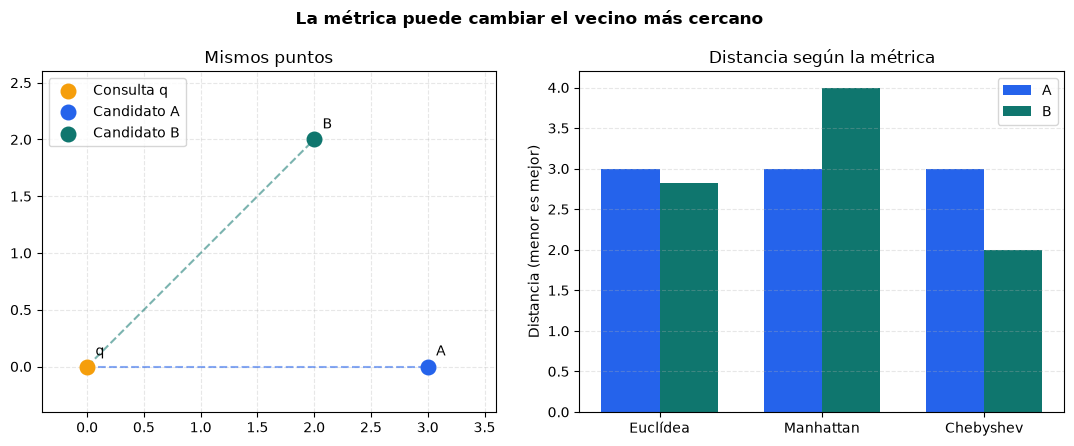

In [12]:
nombres_metricas = list(metricas)
distancias_a = [metrica(consulta, candidatos["A"]) for metrica in metricas.values()]
distancias_b = [metrica(consulta, candidatos["B"]) for metrica in metricas.values()]
posiciones = list(range(len(nombres_metricas)))
ancho_barra = 0.36

fig, (ax_espacio, ax_barras) = plt.subplots(1, 2, figsize=(11, 4.5))

# Izquierda: disposición geométrica de la consulta y los candidatos.
ax_espacio.scatter(0, 0, s=110, color="#f59e0b", label="Consulta q", zorder=3)
ax_espacio.scatter(3, 0, s=110, color="#2563eb", label="Candidato A", zorder=3)
ax_espacio.scatter(2, 2, s=110, color="#0f766e", label="Candidato B", zorder=3)
ax_espacio.plot([0, 3], [0, 0], "--", color="#2563eb", alpha=0.55)
ax_espacio.plot([0, 2], [0, 2], "--", color="#0f766e", alpha=0.55)
ax_espacio.annotate("q", (0, 0), xytext=(6, 8), textcoords="offset points")
ax_espacio.annotate("A", (3, 0), xytext=(6, 8), textcoords="offset points")
ax_espacio.annotate("B", (2, 2), xytext=(6, 8), textcoords="offset points")
ax_espacio.set_xlim(-0.4, 3.6)
ax_espacio.set_ylim(-0.4, 2.6)
ax_espacio.set_aspect("equal")
ax_espacio.grid(True, linestyle="--", alpha=0.3)
ax_espacio.set_title("Mismos puntos")
ax_espacio.legend(loc="upper left")

# Derecha: cada métrica asigna distancias diferentes.
ax_barras.bar(
    [p - ancho_barra / 2 for p in posiciones],
    distancias_a,
    width=ancho_barra,
    label="A",
    color="#2563eb",
)
ax_barras.bar(
    [p + ancho_barra / 2 for p in posiciones],
    distancias_b,
    width=ancho_barra,
    label="B",
    color="#0f766e",
)
ax_barras.set_xticks(posiciones, nombres_metricas)
ax_barras.set_ylabel("Distancia (menor es mejor)")
ax_barras.set_title("Distancia según la métrica")
ax_barras.legend()
ax_barras.grid(axis="y", linestyle="--", alpha=0.3)

fig.suptitle("La métrica puede cambiar el vecino más cercano", weight="bold")
fig.tight_layout()
plt.show()


<details>
<summary><strong>Interpretación</strong></summary>

- Euclídea prefiere B porque $\sqrt{2^2+2^2}\approx2.83<3$.
- Manhattan prefiere A porque $3<2+2$.
- Chebyshev prefiere B porque su mayor salto es 2, frente a 3 para A.

No existe una métrica universalmente mejor: debe reflejar qué significa “cerca” en el problema.
</details>


## 7. El efecto de la escala

Si una componente utiliza números mucho mayores que otra, puede dominar la distancia aunque no sea conceptualmente más importante.

Supón que representamos personas mediante `(edad, ingresos)`. Comparamos una consulta con A y B. En unidades originales, miles de euros pesan mucho más que unos pocos años. Después dividiremos cada componente por un rango de referencia para hacerlas comparables.

> Reescalar no es una operación neutra: incorpora una decisión sobre cuánto debe pesar cada característica.


In [13]:
consulta = [40, 30_000]
candidatos = {
    "A (edad próxima)": [41, 60_000],
    "B (ingresos próximos)": [60, 31_000],
}

def dividir_por_escala(vector, escalas):
    comprobar_mismo_espacio(vector, escalas)
    if any(escala == 0 for escala in escalas):
        raise ValueError("Las escalas no pueden ser cero")
    return [x / escala for x, escala in zip(vector, escalas)]


distancias_originales = {
    nombre: distancia_euclidea(consulta, vector)
    for nombre, vector in candidatos.items()
}

escalas = [40, 80_000]  # rangos de referencia: 40 años y 80 000 €
consulta_reescalada = dividir_por_escala(consulta, escalas)
distancias_reescaladas = {
    nombre: distancia_euclidea(
        consulta_reescalada,
        dividir_por_escala(vector, escalas),
    )
    for nombre, vector in candidatos.items()
}

print("Sin reescalar:", distancias_originales)
print("Vecino:", min(distancias_originales, key=distancias_originales.get))
print()
print("Tras reescalar:", distancias_reescaladas)
print("Vecino:", min(distancias_reescaladas, key=distancias_reescaladas.get))


Sin reescalar: {'A (edad próxima)': 30000.000016666665, 'B (ingresos próximos)': 1000.199980003999}
Vecino: B (ingresos próximos)

Tras reescalar: {'A (edad próxima)': 0.37583240945932267, 'B (ingresos próximos)': 0.500156225593564}
Vecino: A (edad próxima)


## 8. Similitud entre vectores

Una **distancia** suele interpretarse así: menor es mejor. Una **similitud** hace lo contrario: mayor es mejor.

En recuperación es frecuente medir si dos vectores apuntan en una dirección parecida, especialmente cuando el tamaño absoluto —por ejemplo, la longitud de un documento— no debe dominar la comparación.

Dos herramientas fundamentales son el producto escalar y la similitud del coseno.


### Producto escalar

$$\mathbf{a}\cdot\mathbf{b}=\sum_i a_i b_i$$

Geométricamente también puede escribirse como:

$$\mathbf{a}\cdot\mathbf{b}=\|\mathbf{a}\|\|\mathbf{b}\|\cos(\theta)$$

Por ello mezcla dos efectos: **alineación** y **magnitud**.

- positivo: ángulo menor de 90°;
- cero: vectores ortogonales;
- negativo: direcciones opuestas (cuando se permiten componentes negativas).


In [14]:
def producto_escalar(a, b):
    comprobar_mismo_espacio(a, b)
    return sum(x * y for x, y in zip(a, b))


pares = [
    ([1, 0], [2, 0]),   # misma dirección
    ([1, 0], [0, 3]),   # ortogonales
    ([1, 0], [-2, 0]),  # dirección opuesta
]

for a, b in pares:
    print(f"{a} · {b} = {producto_escalar(a, b)}")


[1, 0] · [2, 0] = 2
[1, 0] · [0, 3] = 0
[1, 0] · [-2, 0] = -2


### Similitud del coseno

El coseno divide el producto escalar por las magnitudes:

$$\cos(\mathbf{a},\mathbf{b})=\frac{\mathbf{a}\cdot\mathbf{b}}{\|\mathbf{a}\|\|\mathbf{b}\|}$$

Así se centra en el ángulo. Para vectores con valores no negativos suele estar entre 0 y 1; de forma general, entre -1 y 1.

El coseno con el vector cero no está definido. Nuestra función generará un error claro en ese caso.


In [15]:
def similitud_coseno(a, b):
    comprobar_mismo_espacio(a, b)
    denominador = magnitud(a) * magnitud(b)
    if denominador == 0:
        raise ValueError("El coseno no está definido para el vector cero")
    return producto_escalar(a, b) / denominador


consulta = [1, 1]
documento_corto = [1, 1]
documento_largo = [10, 10]
documento_distinto = [1, 0]

for nombre, documento in (
    ("corto", documento_corto),
    ("largo", documento_largo),
    ("distinto", documento_distinto),
):
    print(
        f"{nombre:8s} | producto={producto_escalar(consulta, documento):5.1f} "
        f"| coseno={similitud_coseno(consulta, documento):.3f}"
    )


corto    | producto=  2.0 | coseno=1.000
largo    | producto= 20.0 | coseno=1.000
distinto | producto=  1.0 | coseno=0.707


El producto escalar favorece al documento largo aunque apunte exactamente en la misma dirección que el corto. El coseno les asigna 1 a ambos: ignora su diferencia de magnitud.

### Normalización + producto escalar = coseno

Si normalizamos ambos vectores, sus magnitudes pasan a ser 1:

$$\hat{\mathbf{a}}\cdot\hat{\mathbf{b}}=
\frac{\mathbf{a}}{\|\mathbf{a}\|}\cdot
\frac{\mathbf{b}}{\|\mathbf{b}\|}=
\cos(\mathbf{a},\mathbf{b})$$

Esta equivalencia es práctica: podemos normalizar una colección una vez y después puntuar mediante productos escalares.


In [16]:
a = [2, 1, 3]
b = [1, 4, 2]

coseno_directo = similitud_coseno(a, b)
producto_normalizados = producto_escalar(normalizar(a), normalizar(b))

print("Coseno directo:                 ", coseno_directo)
print("Producto de vectores normalizados:", producto_normalizados)
print("¿Coinciden?", casi_igual(coseno_directo, producto_normalizados))

assert casi_igual(coseno_directo, producto_normalizados)


Coseno directo:                  0.6998542122237653
Producto de vectores normalizados: 0.6998542122237652
¿Coinciden? True


### Microejercicio 2 — ¿magnitud o dirección?

Para la consulta `q = [1, 1]`, ordena mentalmente estos candidatos:

- `A = [1, 0]`
- `B = [3, 3]`
- `C = [10, 0]`

Hazlo primero mediante producto escalar y después mediante coseno. ¿Por qué cambia el orden?


In [17]:
q = [1, 1]
candidatos = {"A": [1, 0], "B": [3, 3], "C": [10, 0]}

ranking_producto = sorted(
    candidatos,
    key=lambda nombre: producto_escalar(q, candidatos[nombre]),
    reverse=True,
)
ranking_coseno = sorted(
    candidatos,
    key=lambda nombre: similitud_coseno(q, candidatos[nombre]),
    reverse=True,
)

print("Ranking por producto escalar:", ranking_producto)
print("Ranking por coseno:          ", ranking_coseno)


Ranking por producto escalar: ['C', 'B', 'A']
Ranking por coseno:           ['B', 'A', 'C']


<details>
<summary><strong>Solución razonada</strong></summary>

El producto escalar ordena `C > B > A`: la gran magnitud de C domina. El coseno ordena `B > A = C`: B tiene la misma dirección que la consulta, mientras A y C comparten dirección entre sí y forman el mismo ángulo con `q`. Un empate también es información: el sistema necesitaría una regla secundaria para producir un orden total estable.
</details>


## 9. Mini sistema de recuperación: scoring, ranking y top-k

Ya tenemos la maquinaria matemática. Falta representar texto como vectores y conectarlo todo.

Para mantener el foco y usar solo Python estándar construiremos una representación simple:

1. convertimos a minúsculas y extraemos palabras;
2. construimos un vocabulario con todas las palabras de la colección;
3. representamos cada texto mediante sus frecuencias;
4. vectorizamos la consulta en el mismo espacio;
5. calculamos coseno, ordenamos y tomamos los primeros $k$.

Esta representación es deliberadamente sencilla: “vector” y “vectores” serán componentes diferentes y no entiende sinónimos. Es suficiente para observar el sistema completo.


In [18]:
import re
from collections import Counter


def tokenizar(texto):
    """Extrae palabras en minúsculas, conservando letras acentuadas y números."""
    return re.findall(r"\b\w+\b", texto.lower(), flags=re.UNICODE)


def construir_vocabulario(textos):
    """Crea un vocabulario ordenado para que el resultado sea reproducible."""
    return sorted({token for texto in textos for token in tokenizar(texto)})


def vectorizar_frecuencias(texto, vocabulario):
    """Convierte un texto en un vector de conteos usando un vocabulario fijo."""
    conteos = Counter(tokenizar(texto))
    return [conteos[termino] for termino in vocabulario]


coleccion = [
    "La recuperación de información busca documentos relevantes para una consulta.",
    "Los vectores permiten comparar documentos mediante distancias y similitudes.",
    "La similitud del coseno compara la dirección de dos vectores.",
    "Un sistema RAG recupera contexto antes de generar una respuesta.",
    "Las bases de datos relacionales organizan información en tablas.",
    "El ranking ordena documentos según su puntuación de relevancia.",
]

vocabulario = construir_vocabulario(coleccion)
vectores_documentos = [
    vectorizar_frecuencias(documento, vocabulario)
    for documento in coleccion
]

print("Número de documentos:", len(coleccion))
print("Dimensionalidad del espacio:", len(vocabulario))
print("Primeros 15 términos:", vocabulario[:15])


Número de documentos: 6
Dimensionalidad del espacio: 46
Primeros 15 términos: ['antes', 'bases', 'busca', 'compara', 'comparar', 'consulta', 'contexto', 'coseno', 'datos', 'de', 'del', 'dirección', 'distancias', 'documentos', 'dos']


### Inspeccionar una representación

Aunque el vector completo contiene muchos ceros, mostramos solo sus componentes activas para poder leerlo. Sigue siendo conceptualmente el mismo vector de dimensión fija.


In [19]:
def componentes_activas(vector, vocabulario):
    return {
        termino: valor
        for termino, valor in zip(vocabulario, vector)
        if valor != 0
    }


indice = 1  # ✏️ Cambia el índice entre 0 y 5
print("Texto:", coleccion[indice])
print("Componentes no nulas:", componentes_activas(vectores_documentos[indice], vocabulario))


Texto: Los vectores permiten comparar documentos mediante distancias y similitudes.
Componentes no nulas: {'comparar': 1, 'distancias': 1, 'documentos': 1, 'los': 1, 'mediante': 1, 'permiten': 1, 'similitudes': 1, 'vectores': 1, 'y': 1}


### Scoring, ranking y top-k

La función siguiente devuelve registros explícitos con índice, puntuación y texto. Para que los empates sean reproducibles, usa el índice original como segundo criterio.

Una consulta sin ninguna palabra del vocabulario se convierte en el vector cero. Como su coseno no está definido, devolvemos una lista vacía y un mensaje informativo en vez de fabricar puntuaciones.


In [20]:
def recuperar(consulta, documentos, vocabulario, vectores_documentos, k=3):
    """Recupera los k documentos con mayor similitud coseno."""
    if k < 1:
        raise ValueError("k debe ser al menos 1")

    vector_consulta = vectorizar_frecuencias(consulta, vocabulario)
    if magnitud(vector_consulta) == 0:
        print("La consulta no contiene términos conocidos por el sistema.")
        return []

    resultados = []
    for indice, (documento, vector_documento) in enumerate(
        zip(documentos, vectores_documentos)
    ):
        # En esta colección no hay documentos vacíos; protegemos igualmente el caso.
        score = (
            similitud_coseno(vector_consulta, vector_documento)
            if magnitud(vector_documento) > 0
            else 0.0
        )
        resultados.append({
            "indice": indice,
            "score": score,
            "documento": documento,
        })

    ranking = sorted(
        resultados,
        key=lambda resultado: (-resultado["score"], resultado["indice"]),
    )
    return ranking[: min(k, len(ranking))]


consulta = "comparar documentos con vectores"
resultados = recuperar(
    consulta,
    coleccion,
    vocabulario,
    vectores_documentos,
    k=3,
)

print(f"Consulta: {consulta!r}\n")
for posicion, resultado in enumerate(resultados, start=1):
    print(f"{posicion}. score={resultado['score']:.3f}")
    print(f"   {resultado['documento']}")


Consulta: 'comparar documentos con vectores'

1. score=0.577
   Los vectores permiten comparar documentos mediante distancias y similitudes.
2. score=0.192
   El ranking ordena documentos según su puntuación de relevancia.
3. score=0.183
   La recuperación de información busca documentos relevantes para una consulta.


El flujo completo ya está presente:

$$q \rightarrow \text{vectorización} \rightarrow \text{scores} \rightarrow \text{ranking} \rightarrow \text{top-k}$$

Observa que **representación** y **comparación** son decisiones separadas. Podemos mantener el coseno y cambiar cómo obtenemos los vectores, o conservar la representación y probar otra métrica.


### Laboratorio breve

Prueba consultas como:

- `"coseno y dirección"`
- `"información en bases de datos"`
- `"buscar contexto para una respuesta"`
- `"semántica y significado"`

Antes de ejecutar, predice los tres primeros resultados. Después explica los aciertos y errores mirando las palabras compartidas.


In [21]:
mi_consulta = "coseno y dirección"  # ✏️ Escribe aquí tu consulta
mi_k = 3                             # ✏️ Cambia el número de resultados

mis_resultados = recuperar(
    mi_consulta,
    coleccion,
    vocabulario,
    vectores_documentos,
    k=mi_k,
)

for posicion, resultado in enumerate(mis_resultados, start=1):
    print(f"{posicion}. {resultado['score']:.3f} — {resultado['documento']}")


1. 0.333 — La similitud del coseno compara la dirección de dos vectores.
2. 0.192 — Los vectores permiten comparar documentos mediante distancias y similitudes.
3. 0.000 — La recuperación de información busca documentos relevantes para una consulta.


### Microejercicio 3 — Comprueba un límite del sistema

Ejecuta la consulta `"hallar pasajes parecidos"`. Una persona podría relacionarla con recuperación, pero ninguna de esas palabras aparece en la colección.

1. ¿Qué vector produce?
2. ¿Por qué no podemos calcular el coseno?
3. ¿Qué tendría que mejorar para capturar el significado aunque no haya coincidencia literal?


In [22]:
consulta_fuera_vocabulario = "hallar pasajes parecidos"
vector_desconocido = vectorizar_frecuencias(consulta_fuera_vocabulario, vocabulario)

print("Magnitud de la consulta:", magnitud(vector_desconocido))
print("Resultados:")
recuperar(
    consulta_fuera_vocabulario,
    coleccion,
    vocabulario,
    vectores_documentos,
    k=3,
)


Magnitud de la consulta: 0.0
Resultados:
La consulta no contiene términos conocidos por el sistema.


[]

<details>
<summary><strong>Respuesta</strong></summary>

La consulta se convierte en el vector cero porque no contiene términos del vocabulario. El coseno no está definido: su denominador incluye una magnitud cero. Para capturar relaciones semánticas necesitamos una representación más rica, capaz de acercar expresiones relacionadas aunque no compartan exactamente las mismas palabras.
</details>


## 10. Recapitulación

En esta sesión hemos recorrido una cadena completa:

1. **Problema:** dada una consulta, seleccionar información relevante de una colección.
2. **Representación:** convertir elementos en vectores de un espacio común.
3. **Geometría:** interpretar componentes, dimensión, dirección y magnitud.
4. **Operaciones:** sumar, restar, escalar y normalizar.
5. **Comparación:** usar distancias o similitudes.
6. **Decisiones:** reconocer que la métrica, la escala y la normalización alteran los resultados.
7. **Retrieval:** puntuar candidatos, ordenarlos y devolver el top-k.

### Ideas que conviene retener

- Un vector solo es interpretable si sabemos qué significa cada componente.
- “Más cercano” depende de la métrica y de la escala.
- El producto escalar mezcla magnitud y alineación.
- El coseno compara dirección y equivale al producto escalar de vectores normalizados.
- Un ranking puede ser matemáticamente correcto y aun así poco útil si la representación es pobre.


## Puente a la sesión 2: representaciones *sparse* y *dense*

Nuestros vectores de frecuencias contienen muchos ceros: son **sparse** (dispersos). Cada dimensión corresponde a un término identificable, lo que facilita interpretarlos, pero no capturan bien sinónimos, contexto o significado.

En la siguiente sesión compararemos:

- **Representaciones sparse:** muchas dimensiones, muchos ceros y componentes ligadas a términos explícitos.
- **Representaciones dense:** menos dimensiones no interpretables de forma directa, normalmente con valores reales y capaces de capturar relaciones semánticas.

La arquitectura básica seguirá siendo la misma:

$$\text{texto} \rightarrow \text{vector} \rightarrow \text{comparación} \rightarrow \text{ranking} \rightarrow \text{top-k}$$

Lo que cambiará —y cambiará profundamente la calidad del sistema— será la forma de construir el vector.

### Preguntas de salida

1. ¿Por qué dos textos sin palabras compartidas obtienen coseno cero en nuestro sistema?
2. ¿Cuándo preferirías una distancia frente a una similitud?
3. ¿Qué información se pierde al normalizar?
4. ¿Qué parte del mini sistema conservarías al sustituir conteos por *embeddings* densos?
